In [5]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("superstore.csv")
df.head(2)

,Category,City,Country,Customer.ID,Customer.Name,Discount,Market,记录数,Order.Date,Order.ID,...,Sales,Segment,Ship.Date,Ship.Mode,Shipping.Cost,State,Sub.Category,Year,Market2,weeknum
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,1,2011-01-07 00:00:00.000,CA-2011-130813,...,19,Consumer,2011-01-09 00:00:00.000,Second Class,4.37,California,Paper,2011,North America,2
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,1,2011-01-21 00:00:00.000,CA-2011-148614,...,19,Consumer,2011-01-26 00:00:00.000,Standard Class,0.94,California,Paper,2011,North America,4


In [6]:
# Checking Dataset 
df.shape

(51290, 27)

In [7]:
# Checking Columns
df.columns

Index(['Category', 'City', 'Country', 'Customer.ID', 'Customer.Name',
       'Discount', 'Market', '记录数', 'Order.Date', 'Order.ID', 'Order.Priority',
       'Product.ID', 'Product.Name', 'Profit', 'Quantity', 'Region', 'Row.ID',
       'Sales', 'Segment', 'Ship.Date', 'Ship.Mode', 'Shipping.Cost', 'State',
       'Sub.Category', 'Year', 'Market2', 'weeknum'],
      dtype='str')

In [8]:
# Checking Data types 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 27 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Category        51290 non-null  str    
 1   City            51290 non-null  str    
 2   Country         51290 non-null  str    
 3   Customer.ID     51290 non-null  str    
 4   Customer.Name   51290 non-null  str    
 5   Discount        51290 non-null  float64
 6   Market          51290 non-null  str    
 7   记录数             51290 non-null  int64  
 8   Order.Date      51290 non-null  str    
 9   Order.ID        51290 non-null  str    
 10  Order.Priority  51290 non-null  str    
 11  Product.ID      51290 non-null  str    
 12  Product.Name    51290 non-null  str    
 13  Profit          51290 non-null  float64
 14  Quantity        51290 non-null  int64  
 15  Region          51290 non-null  str    
 16  Row.ID          51290 non-null  int64  
 17  Sales           51290 non-null  int64  
 1

In [9]:
# basic statistics
df.describe()

,Discount,记录数,Profit,Quantity,Row.ID,Sales,Shipping.Cost,Year,weeknum
count,51290.000000,51290.0,51290.000000,51290.000000,51290.00000,51290.000000,51290.000000,51290.000000,51290.000000
mean,0.142908,1.0,28.610982,3.476545,25645.50000,246.498440,26.375818,2012.777208,31.287112
std,0.212280,0.0,174.340972,2.278766,14806.29199,487.567175,57.296810,1.098931,14.429795
min,0.000000,1.0,-6599.978000,1.000000,1.00000,0.000000,0.002000,2011.000000,1.000000
25%,0.000000,1.0,0.000000,2.000000,12823.25000,31.000000,2.610000,2012.000000,20.000000
50%,0.000000,1.0,9.240000,3.000000,25645.50000,85.000000,7.790000,2013.000000,33.000000
75%,0.200000,1.0,36.810000,5.000000,38467.75000,251.000000,24.450000,2014.000000,44.000000
max,0.850000,1.0,8399.976000,14.000000,51290.00000,22638.000000,933.570000,2014.000000,53.000000


In [10]:
# Checking data quality 

df.isnull().sum()

Category          0
City              0
Country           0
Customer.ID       0
Customer.Name     0
Discount          0
Market            0
记录数               0
Order.Date        0
Order.ID          0
Order.Priority    0
Product.ID        0
Product.Name      0
Profit            0
Quantity          0
Region            0
Row.ID            0
Sales             0
Segment           0
Ship.Date         0
Ship.Mode         0
Shipping.Cost     0
State             0
Sub.Category      0
Year              0
Market2           0
weeknum           0
dtype: int64

In [11]:
# Checking Dublicates

df.duplicated().sum()

np.int64(0)

In [12]:
# Checking Unique orders   ( Total row counts : 51,290 / unique id we got : 25035) 

df["Order.ID"].nunique()

25035

In [13]:
# Changing Columns name for ( Customer.ID , Order.Date , Shipping.Cost , Sub.Category)

df.columns = (df.columns.str.strip()
    .str.lower()
    .str.replace(".", "_", regex=False)
    .str.replace(" ", "_", regex=False)
)

df.columns

Index(['category', 'city', 'country', 'customer_id', 'customer_name',
       'discount', 'market', '记录数', 'order_date', 'order_id', 'order_priority',
       'product_id', 'product_name', 'profit', 'quantity', 'region', 'row_id',
       'sales', 'segment', 'ship_date', 'ship_mode', 'shipping_cost', 'state',
       'sub_category', 'year', 'market2', 'weeknum'],
      dtype='str')

In [14]:
# We need to delete this column as its not useful for us "记录数"  ( So  we did first renaming than we will delete the column)

df = df.rename(columns={"记录数": "record_count"})

df["record_count"].value_counts()

record_count
1    51290
Name: count, dtype: int64

In [15]:
df.drop(columns=["record_count"], inplace=True)

In [16]:
# Changing Required Data Types

# Date columns
df["order_date"] = pd.to_datetime(df["order_date"])
df["ship_date"] = pd.to_datetime(df["ship_date"])

# ID columns as string
df["customer_id"] = df["customer_id"].astype("string")
df["order_id"] = df["order_id"].astype("string")
df["product_id"] = df["product_id"].astype("string")

In [17]:
df["order_date"].min(), df["order_date"].max()

(Timestamp('2011-01-01 00:00:00'), Timestamp('2014-12-31 00:00:00'))

In [18]:
df.dtypes

category                     str
city                         str
country                      str
customer_id               string
customer_name                str
discount                 float64
market                       str
order_date        datetime64[us]
order_id                  string
order_priority               str
product_id                string
product_name                 str
profit                   float64
quantity                   int64
region                       str
row_id                     int64
sales                      int64
segment                      str
ship_date         datetime64[us]
ship_mode                    str
shipping_cost            float64
state                        str
sub_category                 str
year                       int64
market2                      str
weeknum                    int64
dtype: object

In [19]:
# Creating new date-related columns  

df["order_year"] = df["order_date"].dt.year
df["order_month"] = df["order_date"].dt.month
df["month_name"] = df["order_date"].dt.month_name()
df["quarter"] = df["order_date"].dt.quarter

df["shipping_days"] = (df["ship_date"] - df["order_date"]).dt.days

In [20]:
# Creating Profit Margin %

df["profit_margin_pct"] = (df["profit"] / df["sales"]) * 100

# Handling Sales = 0
df.loc[df["sales"] == 0, "profit_margin_pct"] = None

In [21]:
df.head(2)

,category,city,country,customer_id,customer_name,discount,market,order_date,order_id,order_priority,...,sub_category,year,market2,weeknum,order_year,order_month,month_name,quarter,shipping_days,profit_margin_pct
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,2011-01-07,CA-2011-130813,High,...,Paper,2011,North America,2,2011,1,January,1,2,49.111579
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,2011-01-21,CA-2011-148614,Medium,...,Paper,2011,North America,4,2011,1,January,1,5,48.909474


In [22]:
########## Business KPI Analysis  ##########

# 1. Total Sales
total_sales = df["sales"].sum()
print("total_sales :- ", total_sales)


# 2. Total Profit
total_profit = df["profit"].sum()
print("total_profit :-", total_profit)

# 3. Total Orders
total_orders = df["order_id"].nunique()
print("total_orders :- ", total_orders)

# 4. Total Quantity Sold
total_quantity = df["quantity"].sum()
print("total_quantity :- ",total_quantity)

# 5. Overall Profit Margin %
profit_margin = (total_profit / total_sales) * 100
print("profit_margin :- ",profit_margin)

total_sales :-  12642905
total_profit :- 1467457.2912800002
total_orders :-  25035
total_quantity :-  178312
profit_margin :-  11.606962887722403


In [23]:
########## Category-wise Sales and Profit Analysis   ##########

category_analysis = df.groupby("category")[["sales", "profit"]].sum()
print(category_analysis)

                   sales        profit
category                              
Furniture        4110884  285204.72380
Office Supplies  3787330  518473.83430
Technology       4744691  663778.73318


In [24]:
# Sorting Values by SALES

category_analysis = category_analysis.sort_values( by="sales",ascending=False)
print(category_analysis)

                   sales        profit
category                              
Technology       4744691  663778.73318
Furniture        4110884  285204.72380
Office Supplies  3787330  518473.83430


In [25]:

# Sub-category wise Sales and Profit

result = df.groupby('sub_category')[['sales', 'profit']].sum()
result = result.sort_values('sales', ascending=False)
print(result)

                sales        profit
sub_category                       
Phones        1706874  216717.00580
Copiers       1509439  258567.54818
Chairs        1501682  140396.26750
Bookcases     1466559  161924.41950
Storage       1127124  108461.48980
Appliances    1011081  141680.58940
Machines       779071   58867.87300
Tables         757034  -64083.38870
Accessories    749307  129626.30620
Binders        461952   72449.84600
Furnishings    385609   46967.42550
Art            372163   57953.91090
Paper          244307   59207.68270
Supplies       243090   22583.26310
Envelopes      170926   29601.11630
Fasteners       83254   11525.42410
Labels          73433   15010.51200


In [27]:
# Region-wise Sales and Profit
region = df.groupby('region')[['sales', 'profit']].sum()
print(region.sort_values('sales', ascending=False))

                  sales        profit
region                               
Central         2822399  311403.98164
South           1600960  140355.76618
North           1248192  194597.95252
Oceania         1100207  120089.11200
Southeast Asia   884438   17852.32900
North Asia       848349  165578.42100
EMEA             806184   43897.97100
Africa           783776   88871.63100
Central Asia     752839  132480.18700
West             725514  108418.44890
East             678834   91522.78000
Caribbean        324281   34571.32104
Canada            66932   17817.39000


In [28]:
# Top 10 Countries by Sales

country = df.groupby('country')['sales'].sum()
print(country.sort_values(ascending=False).head(10))

country
United States     2297354
Australia          925257
France             858930
China              700591
Germany            628857
Mexico             622620
India              589664
United Kingdom     528570
Indonesia          404887
Brazil             361098
Name: sales, dtype: int64


In [29]:
# Year-wise Sales and Profit
yearly = df.groupby('order_year')[['sales', 'profit']].sum()
print(yearly)

              sales        profit
order_year                       
2011        2259511  248940.81154
2012        2677493  307415.27910
2013        3405860  406935.23018
2014        4300041  504165.97046


In [30]:
# Discount vs Profit

discount = df.groupby('discount')['profit'].mean()
print(discount)

discount
0.000      61.039514
0.002     125.762649
0.070     140.990022
0.100      63.683426
0.150      50.602409
0.170      38.317107
0.200      23.552594
0.202     -14.518847
0.250       4.043371
0.270      -4.317213
0.300     -57.899557
0.320     -88.560656
0.350    -116.144693
0.370     -78.462191
0.400     -45.246603
0.402    -109.908138
0.450     -41.610973
0.470     -42.982420
0.500     -97.140158
0.550    -315.067200
0.570    -526.129000
0.600     -81.732147
0.602    -213.279085
0.650    -365.997971
0.700    -104.339576
0.800    -122.203244
0.850   -1534.329000
Name: profit, dtype: float64


In [31]:
# Customer Segment Analysis

segment = df.groupby('segment')[['sales', 'profit']].sum()

print(segment)

               sales        profit
segment                           
Consumer     6508141  749239.78206
Corporate    3824808  441208.32866
Home Office  2309956  277009.18056


In [ ]:
################ Charts   ##########################

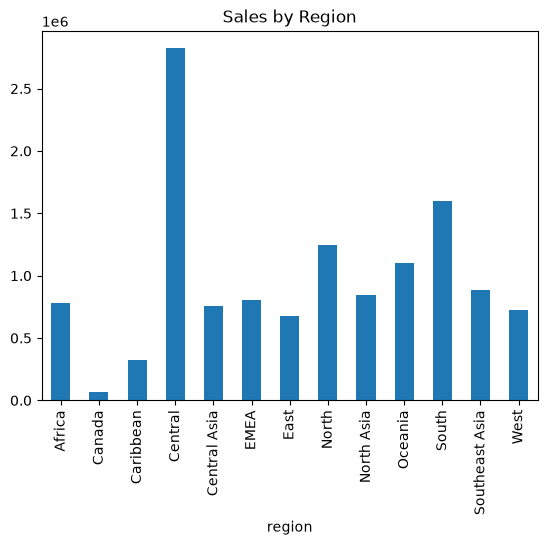

In [32]:
# Chart 1 — Sales by Region

region['sales'].plot(kind='bar', title='Sales by Region')
plt.show()

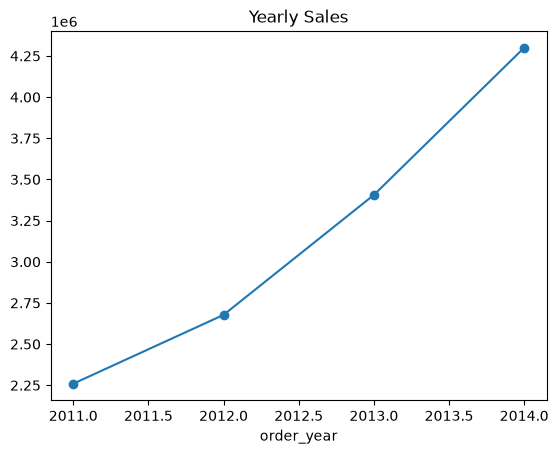

In [38]:
# Chart 2 — Yearly Sales Trend


yearly['sales'].plot(kind='line', marker='o', title='Yearly Sales')
plt.show()

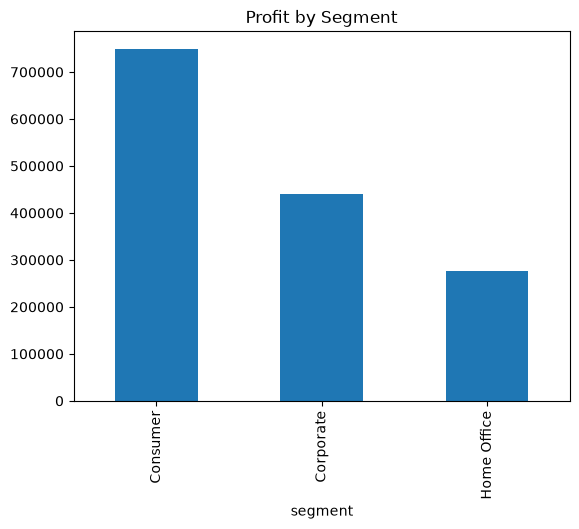

In [37]:
# Chart 3 — Segment-wise Profit

segment['profit'].plot(kind='bar', title='Profit by Segment')
plt.show()

In [ ]:
### Business Insights and Conclusion

1. **Total Sales:** 12.64 million with a total profit of 1.47 million and an overall profit margin of 11.61%.
2. **Best Category:** Technology generated the highest sales (4.74 million) and profit (0.66 million).
3. **Top Sub-category:** Phones generated the highest sales, while Copiers generated the highest profit.
4. **Loss-making Products:** Tables recorded a loss of approximately 64,083.
5. **Top Region:** Central generated the highest sales (2.82 million).
6. **Top Country:** United States contributed the highest sales (2.30 million).
7. **Yearly Growth:** Sales increased every year from 2011 to 2014.
8. **Customer Segment:** Consumer generated the highest sales and profit.
9. **Discount Impact:** Higher discount levels were generally associated with lower average profit.

### Business Recommendations

- Investigate losses in the Tables sub-category.
- Review discount strategies to improve profitability.
- Continue focusing on high-performing Technology products.
- Identify opportunities to improve sales in lower-performing regions.

### Conclusion

The Global Superstore analysis identified key sales trends, profitable products, customer segments, and business improvement opportunities using Python,
Pandas, and Matplotlib.